Model Validation: True

Bayesian Network Nodes:
['Smoking', 'LungDisease', 'Pollution', 'Cough', 'Xray', 'Fatigue']

Bayesian Network Edges:
[('Smoking', 'LungDisease'), ('LungDisease', 'Cough'), ('LungDisease', 'Xray'), ('LungDisease', 'Fatigue'), ('Pollution', 'LungDisease')]

Conditional Probability Distributions:

 +------------+-----+
| Smoking(0) | 0.7 |
+------------+-----+
| Smoking(1) | 0.3 |
+------------+-----+

 +--------------+-----+
| Pollution(0) | 0.6 |
+--------------+-----+
| Pollution(1) | 0.4 |
+--------------+-----+

 +----------------+--------------+--------------+--------------+--------------+
| Smoking        | Smoking(0)   | Smoking(0)   | Smoking(1)   | Smoking(1)   |
+----------------+--------------+--------------+--------------+--------------+
| Pollution      | Pollution(0) | Pollution(1) | Pollution(0) | Pollution(1) |
+----------------+--------------+--------------+--------------+--------------+
| LungDisease(0) | 0.99         | 0.9          | 0.9        

/tmp/ipykernel_1693/741516253.py:161: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


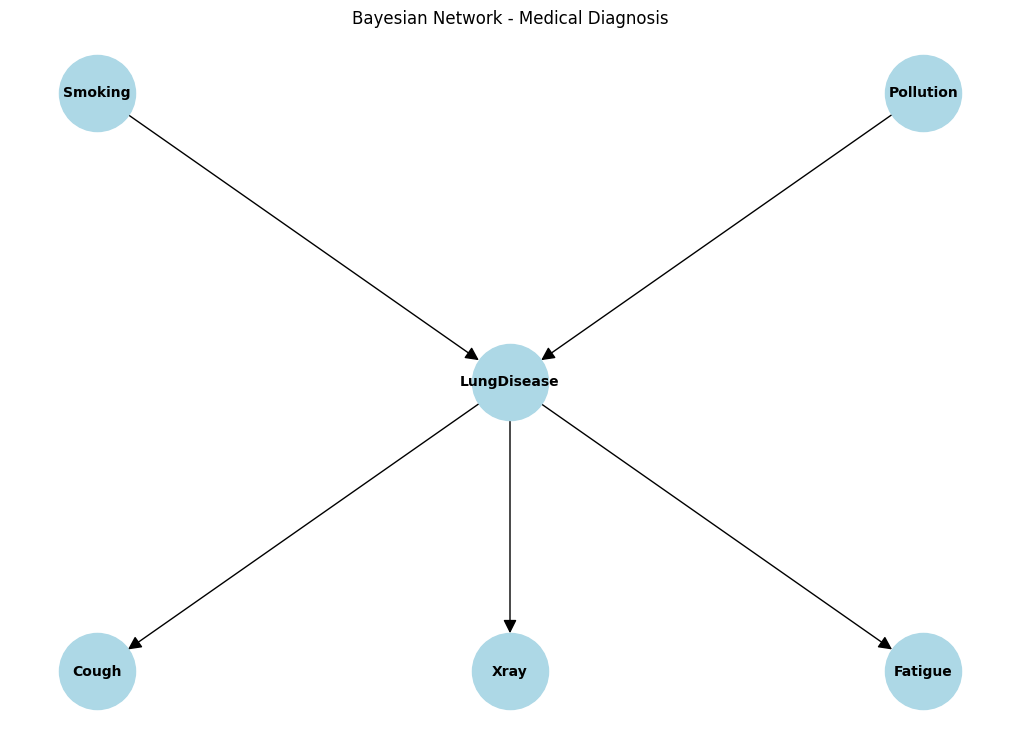


Conditional Independence Information:
Cough is conditionally independent of Smoking
given LungDisease.
Xray is conditionally independent of Pollution
given LungDisease.
Fatigue is conditionally independent of Smoking
given LungDisease.

Active Trail Nodes from Smoking:


AttributeError: 'DiscreteBayesianNetwork' object has no attribute 'get_active_trail_nodes'

In [27]:

# EXPERIMENT 23: BAYESIAN NETWORK CONSTRUCTION AND VISUALIZATION

# Install pgmpy if required
!pip install -q pgmpy

# --------------------------------------------------
# 1. IMPORT LIBRARIES
# --------------------------------------------------

import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

# --------------------------------------------------
# 2. CREATE BAYESIAN NETWORK STRUCTURE
# --------------------------------------------------

model = DiscreteBayesianNetwork([
    ('Smoking', 'LungDisease'),
    ('Pollution', 'LungDisease'),
    ('LungDisease', 'Cough'),
    ('LungDisease', 'Xray'),
    ('LungDisease', 'Fatigue')
])

# --------------------------------------------------
# 3. DEFINE CONDITIONAL PROBABILITY DISTRIBUTIONS
# --------------------------------------------------

# Smoking
cpd_smoking = TabularCPD(
    variable='Smoking',
    variable_card=2,
    values=[[0.7], [0.3]]
)

# Pollution
cpd_pollution = TabularCPD(
    variable='Pollution',
    variable_card=2,
    values=[[0.6], [0.4]]
)

# Lung Disease given Smoking and Pollution
cpd_lung = TabularCPD(
    variable='LungDisease',
    variable_card=2,
    values=[
        [0.99, 0.90, 0.90, 0.70],
        [0.01, 0.10, 0.10, 0.30]
    ],
    evidence=['Smoking', 'Pollution'],
    evidence_card=[2, 2]
)

# Cough given Lung Disease
cpd_cough = TabularCPD(
    variable='Cough',
    variable_card=2,
    values=[
        [0.80, 0.30],
        [0.20, 0.70]
    ],
    evidence=['LungDisease'],
    evidence_card=[2]
)

# X-ray given Lung Disease
cpd_xray = TabularCPD(
    variable='Xray',
    variable_card=2,
    values=[
        [0.90, 0.20],
        [0.10, 0.80]
    ],
    evidence=['LungDisease'],
    evidence_card=[2]
)

# Fatigue given Lung Disease
cpd_fatigue = TabularCPD(
    variable='Fatigue',
    variable_card=2,
    values=[
        [0.70, 0.40],
        [0.30, 0.60]
    ],
    evidence=['LungDisease'],
    evidence_card=[2]
)

# --------------------------------------------------
# 4. ADD CPDs TO THE MODEL
# --------------------------------------------------

model.add_cpds(
    cpd_smoking,
    cpd_pollution,
    cpd_lung,
    cpd_cough,
    cpd_xray,
    cpd_fatigue
)

# --------------------------------------------------
# 5. VALIDATE THE MODEL
# --------------------------------------------------

print("Model Validation:", model.check_model())

print("\nBayesian Network Nodes:")
print(list(model.nodes()))

print("\nBayesian Network Edges:")
print(list(model.edges()))

# --------------------------------------------------
# 6. DISPLAY CPDs
# --------------------------------------------------

print("\nConditional Probability Distributions:")

for cpd in model.get_cpds():
    print("\n", cpd)

# --------------------------------------------------
# 7. VISUALIZE BAYESIAN NETWORK
# --------------------------------------------------

G = nx.DiGraph()

G.add_edges_from(model.edges())

pos = {
    'Smoking': (0, 2),
    'Pollution': (2, 2),
    'LungDisease': (1, 1),
    'Cough': (0, 0),
    'Xray': (1, 0),
    'Fatigue': (2, 0)
}

plt.figure(figsize=(10, 7))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='lightblue',
    font_size=10,
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network - Medical Diagnosis")
plt.axis('off')
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. DISPLAY CONDITIONAL INDEPENDENCIES
# --------------------------------------------------

print("\nConditional Independence Information:")

print("Cough is conditionally independent of Smoking")
print("given LungDisease.")

print("Xray is conditionally independent of Pollution")
print("given LungDisease.")

print("Fatigue is conditionally independent of Smoking")
print("given LungDisease.")

# --------------------------------------------------
# 9. CHECK ACTIVE TRAILS
# --------------------------------------------------

print("\nActive Trail Nodes from Smoking:")

active_nodes = model.get_active_trail_nodes(
    'Smoking',
    observed=[]
)

print(active_nodes)

print("\nActive Trail Nodes from Smoking when LungDisease is observed:")

active_nodes_observed = model.get_active_trail_nodes(
    'Smoking',
    observed=['LungDisease']
)

print(active_nodes_observed)

# --------------------------------------------------
# 10. DISPLAY FINAL RESULT
# --------------------------------------------------

print("\nExperiment 23 Completed Successfully!")
print("Bayesian Network constructed.")
print("CPDs defined and added.")
print("Model validated.")
print("Network visualization generated.")
